<a href="https://colab.research.google.com/github/adriann-engcomp/adriann-engcomp/blob/main/aula_01_exploracao_dataset_Iris.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Explorando um *dataset*

Vamos trabalhar com um dos *datasets* mais clássicos da literatura de *machine learning*, a saber, o conjunto Iris.

## 1. Descrição do *dataset*

Fonte: https://scikit-learn.org/stable/datasets/toy_dataset.html

❗ **COMPLETE COM AS INFORMAÇÕES GERAIS DO DATASET** ❗



In [1]:
""" Carregando os pacotes necessários """
from sklearn.datasets import load_iris
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Veja a descrição da função `load_iris()`.

In [2]:
#Carregando o dataset Iris na forma de um Bunch
iris = load_iris(as_frame=True)

## 1. Primeiras impressões

Vamos explorar o objeto denominado iris e conhecer algumas de suas propriedades.

❗**PREENCHER O CÓDIGO ABAIXO**❗

In [8]:
""" ANALISE ALGUNS ATRIBUTOS DO OBJETO IRIS  """


#DataFrame único
df = iris.frame

#Primeiras cinco amostras
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


É interessante ter uma versão do DataFrame com uma coluna adicional indicando os nomes das espécies, em vez dos rótulos numéricos. Para isso, vamos usar um mapeamento fixo dos rótulos {0,1,2} para as classes {setosa, versicolor, virginica}.


In [9]:
labels = {0: 'setosa', 1: 'versicolor',
            2: 'virginica'}

# Acrescenta a coluna 'labels' mapeando os valores de 'target' conforme o dicionário criado
df['labels'] = df['target'].map(labels)

❗**Insira abaixo alguns comandos para visualizar o conteúdo do *dataset* carregado.**❗


In [11]:
""" CÓDIGO AQUI """

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,labels
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


## Visualização das amostras para cada par de atributos

Como temos apenas 4 atributos, é factível visualizar o espalhamento das amostras olhando isoladamente para cada par de atributos.

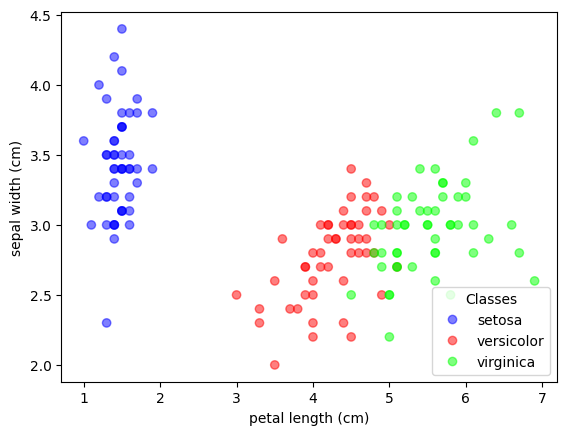

In [16]:
#índices dos atributos para formar o par
ii = 2
jj = 1

_, ax = plt.subplots()
scatter = ax.scatter(df.iloc[:, ii], df.iloc[:, jj], c=df["target"],cmap="brg",alpha=0.5)

ax.set(xlabel=iris.feature_names[ii], ylabel=iris.feature_names[jj])
_ = ax.legend(
    scatter.legend_elements()[0], iris.target_names, loc="lower right", title="Classes"
)

O que você conseguir perceber através desses gráficos?

❗**COMENTE**❗

Uma forma mais direta de gerar todos esses gráficos explora o `seaborn`

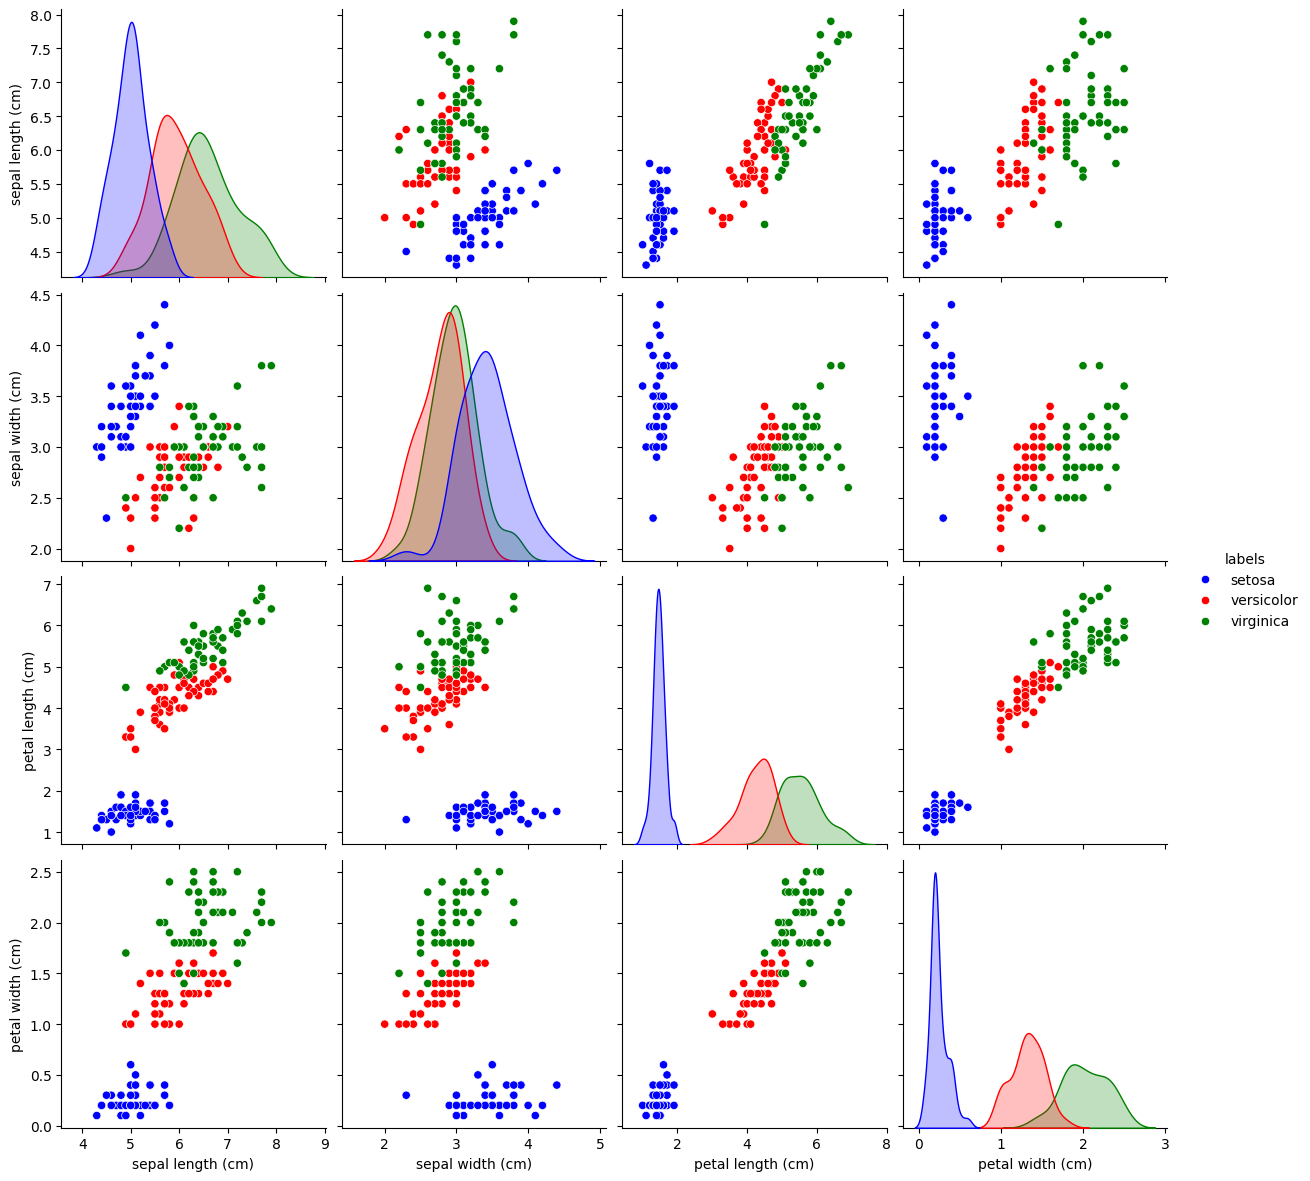

In [17]:
#Obs.: ao passar o dataframe, retiramos a coluna "target" para não tratarmos ela junto aos outros atributos
sns.pairplot(data = df.drop("target",axis='columns'), hue="labels", height=3, palette = ['blue','red','green'])
plt.show()

## Distribuição dos valores de cada *feature*

Outra análise interessante consiste em verificar os histogramas das amostras do *dataset* separadas por classe em função de cada parâmetro de entrada.

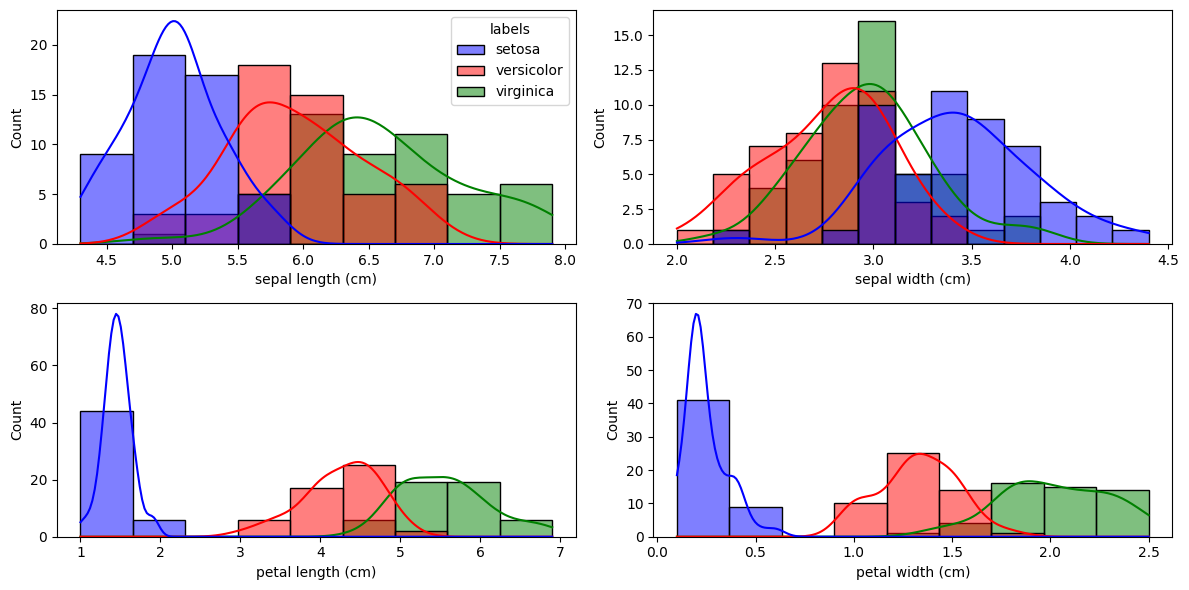

In [18]:
fig, axs = plt.subplots(2, 2, figsize=(12, 6))
for col, ax in zip(df.columns[:4], axs.flat):
    sns.histplot(data=df, x=col, kde=True, hue='labels', common_norm=False, palette = ['blue','red','green'],legend=ax==axs[0,0], ax=ax)
plt.tight_layout()
plt.show()

O que se conclui a partir dessas figuras?

❗**COMPLETAR**❗

## Boxplots para cada atributo

Outra forma de olhar para cada atributo se dá por meio de gráficos de caixa (*boxplots*).

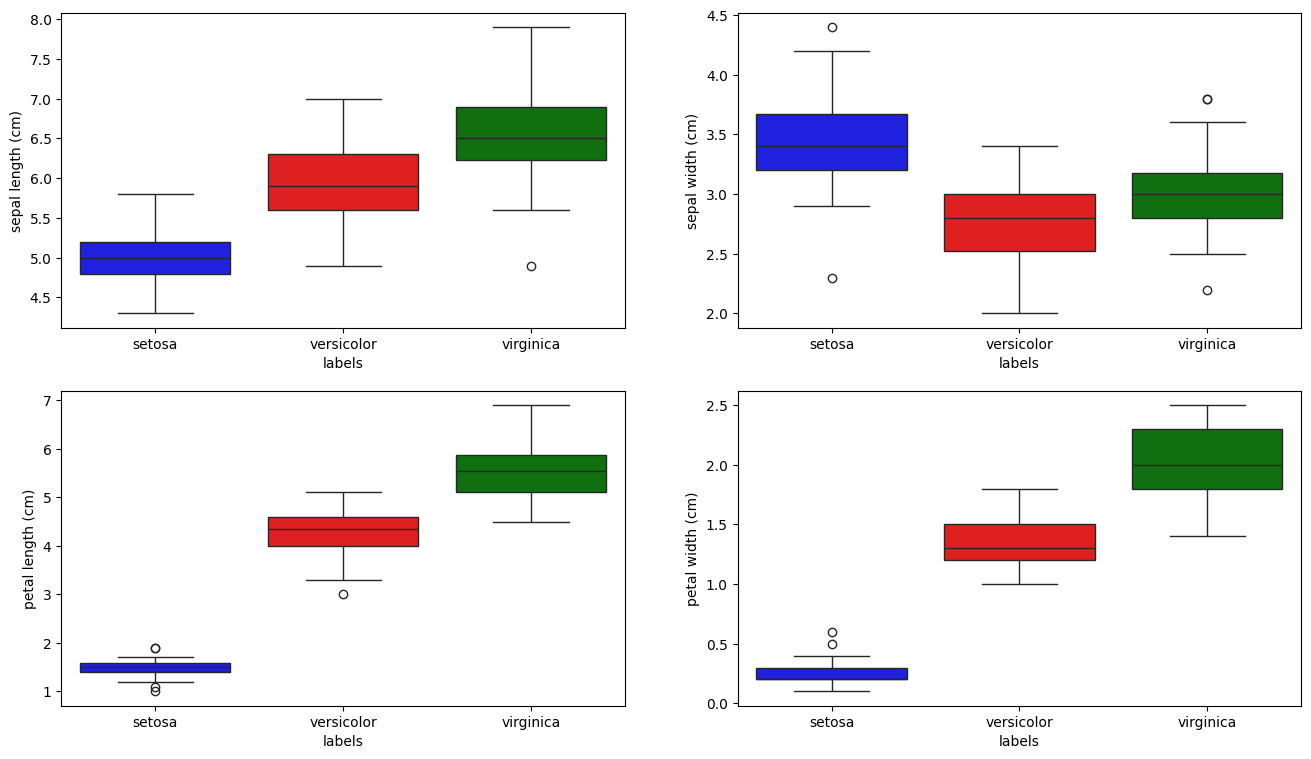

In [19]:
fig, axs = plt.subplots(2, 2, figsize=(16, 9))

for col, ax in zip(df.columns[:4], axs.flat):
    sns.boxplot(x="labels", y=col, hue='labels', palette = ['blue','red','green'], data=df, ax=ax)
plt.show()

## Correlação cruzada entre os atributos e os rótulos

Também é pertinente considerar qual a relação (estatística) existente entre os atributos.

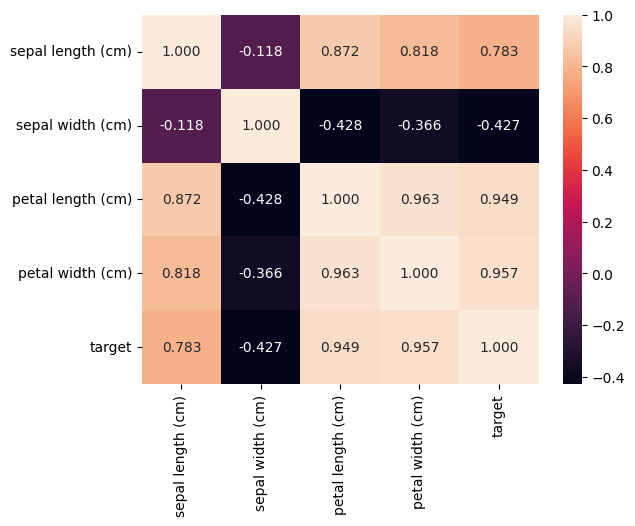

In [25]:
df2 = df.drop("labels",axis=1)

sns.heatmap(df2.corr(),annot=True, fmt=".3f")
plt.show()

Observações:

❗**PREENCHER**❗

## Separabilidade das classes - Visualização dos dados em duas dimensões

Tamanho do array: (150, 4)


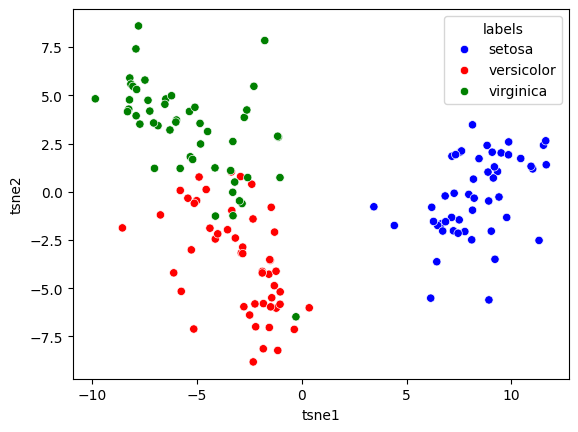

In [23]:
#extrai do DataFrame um array com as 150 amostras representadas por seus 4 atributos
X = df.iloc[:,:4].values
print(f'Tamanho do array: {X.shape}')

from sklearn import manifold

""" Vamos usar uma técnica chamada t-SNE para mapear os dados numa representação 2D de forma não-linear buscando preservar as relações
    de vizinhança (probabilística) entre as amostras.
"""
t_sne = manifold.TSNE(
    n_components=2,
    perplexity=5,
    init="random",
    max_iter=250,
    random_state=0,
)
X_t_sne = t_sne.fit_transform(X)

#plt.figure()
#plt.scatter(X_t_sne[:, 0], X_t_sne[:, 1],c=df['target'],cmap='brg')
#plt.legend(label_names)

tsne_result = pd.concat([
    #apenas garante que os índices das linhas voltem ao formato original (0, 1, ...) e coloca os labels como primeira coluna
    df.reset_index()[['labels']],
    pd.DataFrame(X_t_sne,columns=['tsne1','tsne2'])
],axis=1)

#Exibe a visualização dos dados no espaço 2D
sns.scatterplot(data = tsne_result, x = "tsne1", y = "tsne2",hue = "labels",palette = ['blue','red','green'])
plt.show()

**Considerações finais:**

❗**COMENTE**❗